# Regularization and Gradient Descent Exercises
![UnderOverFit.png](Assets/UnderOverFit.png)


# Obiectivele învățării

- Explicarea funcțiilor de cost, regularizarea, selectarea caracteristicilor și hiperparametrii
- Rezumarea algoritmilor de optimizare statistică complexă, cum ar fi coborârea gradientului și aplicarea sa la regresia liniară



## Introducere

Vom începe cu un scurt tutorial despre regresie, caracteristici polinomiale și regularizare, bazat pe un set de date foarte simplu, rar, care conține o coloană de date `x` și date zgomotoase asociate `y`. Fișierul de date se numește `X_Y_Sinusoid_Data.csv`. 

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

DATA_DIR = 'data' if os.path.isdir('data') else '.'
RANDOM_STATE = 42

def load_ames():
    """Încarcă setul Ames (CSV dacă există, altfel XLSX)."""
    csv  = os.path.join(DATA_DIR, 'Ames_Housing_Sales.csv')
    xlsx = os.path.join(DATA_DIR, 'Ames_Housing_Sales.xlsx')
    return pd.read_csv(csv) if os.path.exists(csv) else pd.read_excel(xlsx)

## Întrebare 1

* Importați datele. 

* De asemenea, generați aproximativ 100 de puncte de date x egal distanțate pe intervalul 0-1. Folosind aceste puncte, calculați datele y care reprezintă „adevărul de bază” (funcția reală) din ecuația: $y = sin(2\pi x)$

* Reprezentați grafic datele rarefiate (`x` vs `y`) și datele calculate („reale”).


Forma datelor rarefiate: (20, 2)


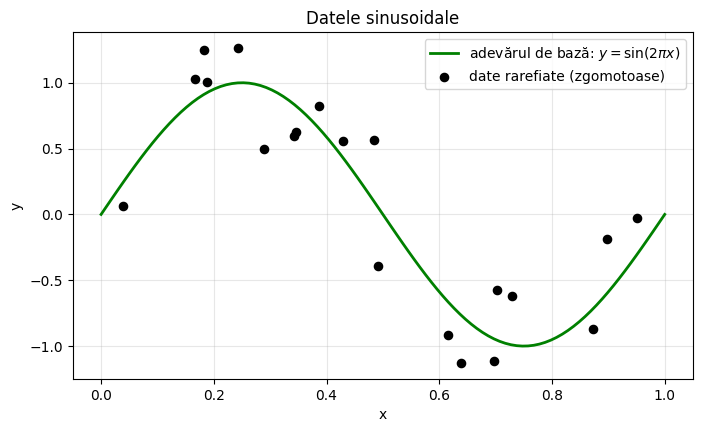

In [2]:
# Datele rarefiate (zgomotoase)
sin_data = pd.read_csv(os.path.join(DATA_DIR, 'X_Y_Sinusoid_Data.csv'))
print("Forma datelor rarefiate:", sin_data.shape)

# „Adevărul de bază”: ~100 de puncte egal distanțate pe [0, 1]
x_true = np.linspace(0, 1, 100)
y_true = np.sin(2 * np.pi * x_true)

plt.figure(figsize=(8, 4.5))
plt.plot(x_true, y_true, 'g-', lw=2, label=r'adevărul de bază: $y=\sin(2\pi x)$')
plt.scatter(sin_data['x'], sin_data['y'], c='k', s=35, label='date rarefiate (zgomotoase)', zorder=3)
plt.xlabel('x'); plt.ylabel('y'); plt.title('Datele sinusoidale'); plt.legend(); plt.grid(alpha=.3)
plt.show()

**Răspuns.** Setul rarefiat are **20 de puncte** zgomotoase în jurul sinusoidei adevărate $y=\sin(2\pi x)$ (curba verde, calculată pe 100 de puncte egal distanțate în [0, 1]).

## Întrebarea 2


* Folosind clasa `PolynomialFeatures` din biblioteca de preprocesare Scikit-learn, creați caracteristici polinomiale de ordinul 20.
* Adaptați aceste date folosind regresia liniară. 
* Reprezentați grafic valoarea prezisă rezultată în comparație cu datele calculate.

Rețineți că `PolynomialFeatures` necesită fie un cadru de date (cu o coloană, nu o serie), fie o matrice 2D de dimensiune (`X`, 1), unde `X` este lungimea.

Formă caracteristici polinomiale: (20, 21) (puține puncte, 21 de caracteristici)


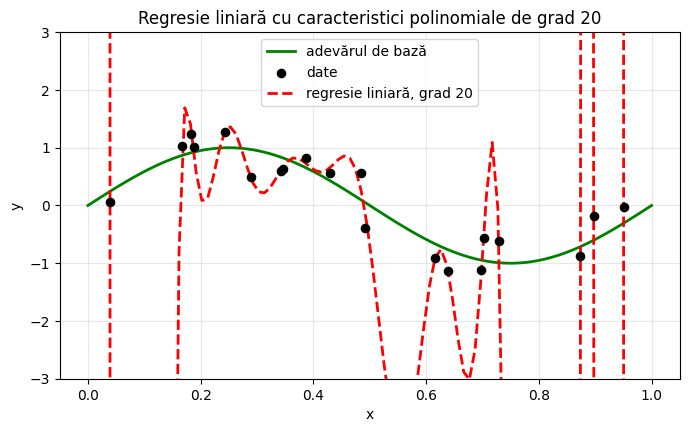

RMSE pe punctele de antrenare: 0.100016
Magnitudinea maximă a coeficienților: 9.200e+11


In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X_s = sin_data[['x']]                      # DataFrame cu o coloană (formă (n, 1))
y_s = sin_data['y']

poly = PolynomialFeatures(degree=20)
X_poly = poly.fit_transform(X_s)           # 1, x, x^2, ..., x^20
print("Formă caracteristici polinomiale:", X_poly.shape, "(puține puncte, 21 de caracteristici)")

lr_s = LinearRegression().fit(X_poly, y_s)
y_lr = lr_s.predict(poly.transform(pd.DataFrame({'x': x_true})))

plt.figure(figsize=(8, 4.5))
plt.plot(x_true, y_true, 'g-', lw=2, label='adevărul de bază')
plt.scatter(sin_data['x'], sin_data['y'], c='k', s=35, label='date', zorder=3)
plt.plot(x_true, y_lr, 'r--', lw=2, label='regresie liniară, grad 20')
plt.ylim(-3, 3); plt.xlabel('x'); plt.ylabel('y'); plt.title('Regresie liniară cu caracteristici polinomiale de grad 20')
plt.legend(); plt.grid(alpha=.3); plt.show()
print("RMSE pe punctele de antrenare:", np.sqrt(np.mean((lr_s.predict(X_poly) - y_s) ** 2)).round(6))
print("Magnitudinea maximă a coeficienților:", f"{np.abs(lr_s.coef_).max():.3e}")

**Răspuns.** Cu caracteristici polinomiale de grad 20 avem **21 de caracteristici pentru doar 20 de puncte**: sistemul este nedeterminat, iar modelul poate trece (aproape) prin toate punctele (RMSE pe antrenare ≈ 0,10, deci doar zgomotul rămâne neexplicat), dar între puncte curba **oscilează violent** și iese mult din intervalul [-1, 1] (graficul este tăiat la ±3). Este o **supraadaptare** extremă (fenomenul Runge): modelul memorează zgomotul. Coeficienții ajung la magnitudini uriașe, ≈ **9,2·10¹¹**.

## Întrebare 3

* Efectuați regresia pe baza datelor cu caracteristici polinomiale utilizând regresia Ridge ($\alpha$=0,001) și regresia Lasso ($\alpha$=0,0001). 
* Reprezentați grafic rezultatele, așa cum s-a făcut la întrebarea 1. 
* De asemenea, reprezentați grafic magnitudinea coeficienților obținuți din aceste regresii și comparați-i cu cei obținuți din regresia liniară din întrebarea anterioară. Coeficienții regresiei liniare vor necesita probabil un grafic separat (sau propria axă y) din cauza magnitudinii lor mari. 

Ce vă spune magnitudinea comparativ mare a datelor cu privire la rolul regularizării?

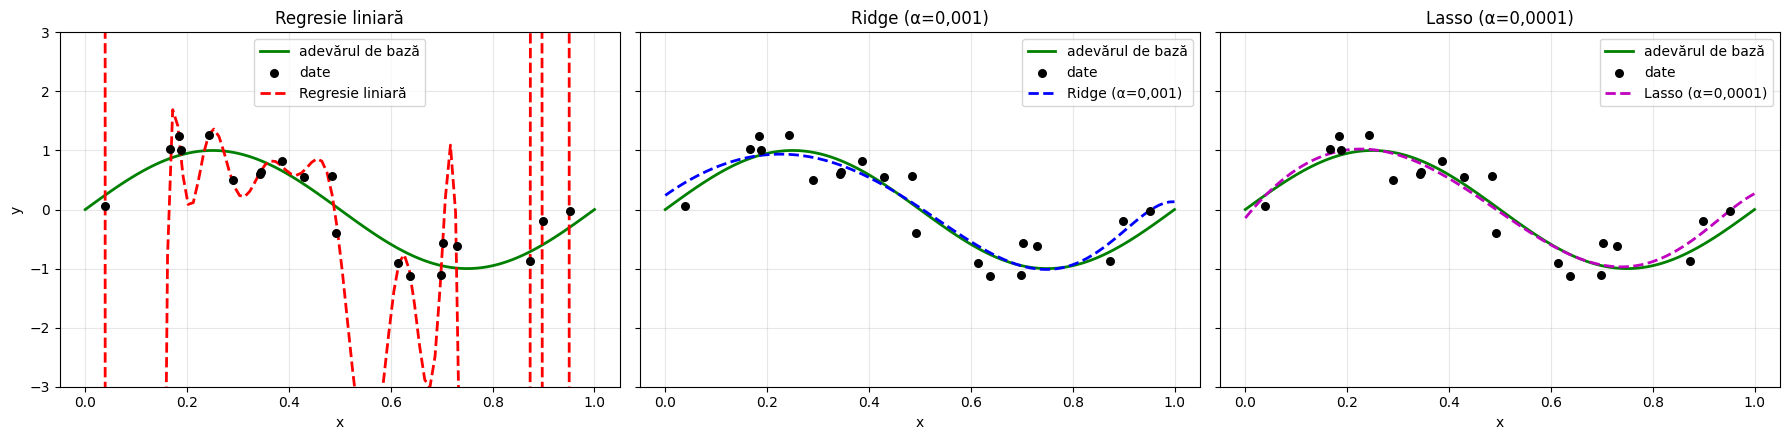

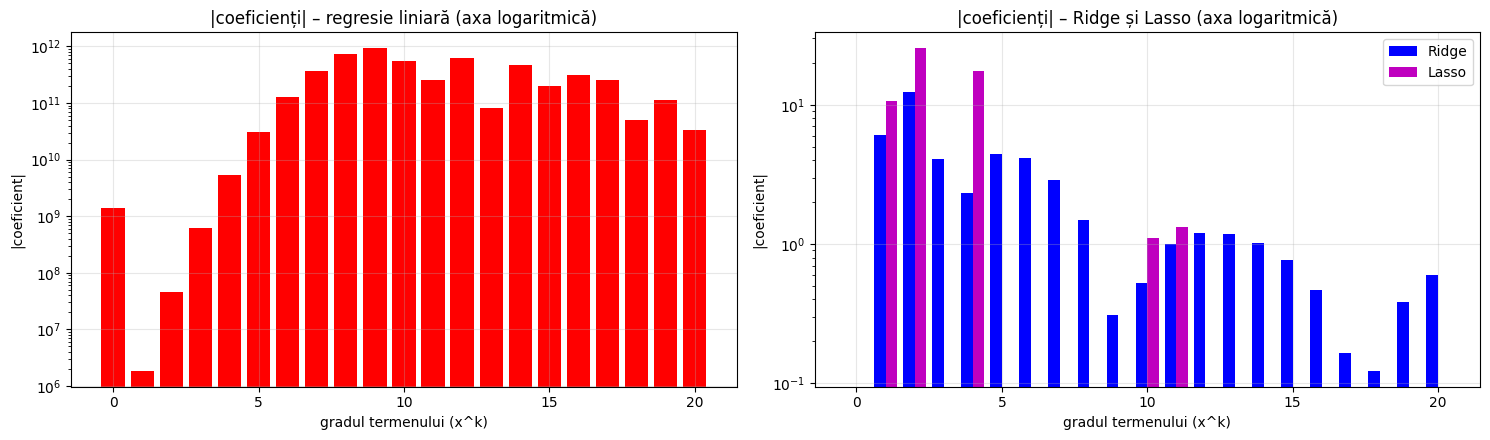

Magnitudine maximă |coef|:
Liniară    9.200e+11
Ridge      1.243e+01
Lasso      2.536e+01
dtype: str

Coeficienți egali cu 0 (Lasso): 16 din 21


In [4]:
from sklearn.linear_model import Ridge, Lasso

ridge_s = Ridge(alpha=0.001).fit(X_poly, y_s)
lasso_s = Lasso(alpha=0.0001, max_iter=1_000_000).fit(X_poly, y_s)

grid_poly = poly.transform(pd.DataFrame({'x': x_true}))
y_ridge, y_lasso = ridge_s.predict(grid_poly), lasso_s.predict(grid_poly)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for a, yy, name, col in zip(ax, [y_lr, y_ridge, y_lasso],
                            ['Regresie liniară', 'Ridge (α=0,001)', 'Lasso (α=0,0001)'], ['r', 'b', 'm']):
    a.plot(x_true, y_true, 'g-', lw=2, label='adevărul de bază')
    a.scatter(sin_data['x'], sin_data['y'], c='k', s=30, zorder=3, label='date')
    a.plot(x_true, yy, col + '--', lw=2, label=name)
    a.set_ylim(-3, 3); a.set_title(name); a.set_xlabel('x'); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel('y'); plt.tight_layout(); plt.show()

# ---- Magnitudinea coeficienților ----
coef = pd.DataFrame({'Liniară': lr_s.coef_, 'Ridge': ridge_s.coef_, 'Lasso': lasso_s.coef_})
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(range(21), coef['Liniară'].abs(), color='r'); ax[0].set_yscale('log')
ax[0].set_title('|coeficienți| – regresie liniară (axa logaritmică)')
w = 0.4
ax[1].bar(np.arange(21) - w/2, coef['Ridge'].abs(), w, label='Ridge', color='b')
ax[1].bar(np.arange(21) + w/2, coef['Lasso'].abs(), w, label='Lasso', color='m')
ax[1].set_yscale('log'); ax[1].set_title('|coeficienți| – Ridge și Lasso (axa logaritmică)'); ax[1].legend()
for a in ax: a.set_xlabel('gradul termenului (x^k)'); a.set_ylabel('|coeficient|'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Magnitudine maximă |coef|:")
print(coef.abs().max().apply(lambda v: f"{v:.3e}"))
print("\nCoeficienți egali cu 0 (Lasso):", int((lasso_s.coef_ == 0).sum()), "din 21")

**Răspuns.** Atât Ridge (α = 0,001), cât și Lasso (α = 0,0001) produc curbe netede, apropiate de sinusoida adevărată, în ciuda aceluiași număr de caracteristici.

Magnitudinea maximă a coeficienților: **regresie liniară ≈ 9,2·10¹¹**, **Ridge ≈ 12,4**, **Lasso ≈ 25,4**; adică diferență de ~10 ordine de mărime. În plus, **Lasso setează exact pe 0 un număr de 16 din 21 de coeficienți**, deci păstrează doar 5 termeni polinomiali (selecție de caracteristici), pe când Ridge îi micșorează pe toți, fără să îi anuleze.

**Ce ne spune magnitudinea mare a coeficienților din regresia liniară?** Coeficienții uriași, de semne alternante, se anulează reciproc pentru a trece prin fiecare punct de date: este *semnătura supraadaptării* (varianță mare). Regularizarea adaugă un cost pentru mărimea coeficienților (L2 pentru Ridge: $\alpha\sum w_j^2$; L1 pentru Lasso: $\alpha\sum |w_j|$), deci **limitează complexitatea efectivă a modelului**, acceptă puțin bias în schimbul unei scăderi mari a varianței și duce la o funcție mai netedă, care generalizează mai bine.

## Întrebarea 4

Pentru întrebările rămase, vom lucra cu [setul de date](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) din lecția trecută, care se bazează pe prețurile locuințelor din Ames, Iowa. Există un număr mare de caracteristici - a se vedea exercițiile din săptămâna a treia pentru o discuție despre aceste caracteristici.

Pentru a începe:

* Importați datele cu Pandas, eliminați orice valori nule și o codificare fierbinte a categoriilor. Pot fi utilizate fie codificatoarele de caracteristici Scikit-learn, fie metoda Pandas `get_dummies`.
* Împărțiți datele în seturi de instruire și de testare. 
* Transformarea logaritmică a caracteristicilor distorsionate. 
* Se poate încerca scalarea, deși poate fi interesant să se vadă cât de bine funcționează regularizarea fără scalarea caracteristicilor.

In [5]:
from sklearn.model_selection import train_test_split

data = load_ames()
print("Forma:", data.shape)

# Calitate date: LotFrontage are 251 de valori imposibile (~1e16; maximul real în Ames este ~313 ft) -> le tratăm ca lipsă
data.loc[data['LotFrontage'] > 1000, 'LotFrontage'] = np.nan

cat_cols = data.select_dtypes(include=['object', 'string']).columns.tolist()
print("Rânduri rămase dacă am elimina toate rândurile cu valori nule:", len(data.dropna()), "din", len(data))

# „Eliminarea” valorilor nule se face prin completare, nu prin ștergerea rândurilor:
#  - categoriale: lipsa înseamnă „fără acea caracteristică" -> categoria 'None'
#  - numerice (LotFrontage, MasVnrArea, GarageYrBlt): mediana de pe setul de antrenare (după împărțire)
data[cat_cols] = data[cat_cols].fillna('None')
print("Coloane categoriale:", len(cat_cols))

Forma: (1379, 80)
Rânduri rămase dacă am elimina toate rândurile cu valori nule: 0 din 1379
Coloane categoriale: 43


**Răspuns.** Dacă am elimina toate rândurile cu valori nule am rămâne cu **0 rânduri din 1379** (multe coloane categoriale au lipsuri pentru case fără alee, piscină, șemineu etc.). De aceea „eliminăm” valorile nule prin **completare**: pentru categoriale, lipsa devine categoria `None` (casa nu are acea caracteristică), iar pentru cele numerice se folosește mediana din setul de antrenare (după împărțire, pentru a nu scurge informație din test). Coloana `LotFrontage` avea și valori imposibile (≈ 10¹⁶) în 251 de rânduri, pe care le-am tratat drept lipsă.

Creați o listă de date categoriale și codificați one-hot. Pandas one-hot encoder (`get_dummies`) funcționează bine cu date care sunt definite ca fiind categoriale.

In [6]:
# One-hot cu Pandas get_dummies (coloanele sunt definite ca „category”)
data[cat_cols] = data[cat_cols].astype('category')
data_ohe = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)
print("După one-hot:", data_ohe.shape)

După one-hot: (1379, 252)


Apoi, împărțiți datele în seturi de date de instruire și de testare.

In [7]:
train, test = train_test_split(data_ohe, test_size=0.3, random_state=RANDOM_STATE)
train, test = train.copy(), test.copy()

# Completăm lipsurile numerice cu mediana din antrenare
num_nulls = train.columns[train.isnull().any() | test.isnull().any()].tolist()
print("Coloane numerice cu lipsuri:", num_nulls)
for c in num_nulls:
    med = train[c].median()
    train[c] = train[c].fillna(med); test[c] = test[c].fillna(med)
print("Train:", train.shape, "| Test:", test.shape, "| lipsuri rămase:", int(train.isnull().sum().sum() + test.isnull().sum().sum()))

Coloane numerice cu lipsuri: ['LotFrontage']
Train: (965, 252) | Test: (414, 252) | lipsuri rămase: 0


Există o serie de coloane care au caracteristici înclinate - li se poate aplica o transformare logaritmică. Rețineți că aceasta include `SalePrice`, predictorul nostru. Cu toate acestea, să o păstrăm așa cum este.

Transformați toate coloanele în care deviația este mai mare de 0,75, cu excepția „SalePrice”.

In [8]:
# Coloanele numerice originale (nu dummy) – excludem SalePrice
num_orig = [c for c in data.columns if c not in cat_cols and c != 'SalePrice']
skew = train[num_orig].skew()
skewed_cols = skew[skew.abs() > 0.75].index.tolist()
print(f"{len(skewed_cols)} din {len(num_orig)} coloane numerice au |skew| > 0.75 (calculat pe train):")
print(skew[skewed_cols].sort_values(ascending=False).round(2).head(10).to_dict())

for df_ in (train, test):
    df_[skewed_cols] = np.log1p(df_[skewed_cols].clip(lower=0))      # log(1+x): sigur pentru valori 0

23 din 36 coloane numerice au |skew| > 0.75 (calculat pe train):
{'MiscVal': 26.92, 'PoolArea': 15.78, 'LotArea': 11.5, 'LowQualFinSF': 11.21, '3SsnPorch': 10.15, 'KitchenAbvGr': 5.5, 'ScreenPorch': 4.6, 'BsmtFinSF2': 4.47, 'BsmtHalfBath': 3.88, 'EnclosedPorch': 3.22}


**Răspuns.** 23 din cele 36 de coloane numerice originale au asimetrie |skew| > 0,75 (calculată pe train, excluzând `SalePrice` și coloanele one-hot, pentru care o transformare logaritmică nu are sens). Le-am aplicat `log(1+x)`, ceea ce comprimă cozile lungi (de ex. `MiscVal`, `PoolArea`, `LotArea`).

Separate features from predictor.

In [9]:
X_train, y_train = train.drop(columns='SalePrice'), train['SalePrice']
X_test,  y_test  = test.drop(columns='SalePrice'),  test['SalePrice']
print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (965, 251)  X_test: (414, 251)


## Întrebare 5

* Scrieți o funcție **`rmse`** care primește valorile de adevăr și predicție și returnează eroarea medie pătratică. Utilizați funcția `mean_squared_error` de la sklearn.  


In [10]:
from sklearn.metrics import mean_squared_error, make_scorer

def rmse(y_true, y_pred):
    """Rădăcina erorii pătratice medii (RMSE)."""
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(rmse, greater_is_better=False)   # pentru cross-validation / CV-uri sklearn
print("Test rmse:", rmse(np.array([1., 2, 3]), np.array([1., 2, 5])).round(4), "(așteptat sqrt(4/3) = 1.1547)")

Test rmse: 1.1547 (așteptat sqrt(4/3) = 1.1547)


* Adaptați un model de regresie liniară de bază
* tipăriți eroarea medie pătratică pentru acest model
* reprezentați grafic prețul de vânzare previzionat față de cel real pe baza modelului.  

RMSE regresie liniară  | train: 20,209 $ | test: 78,539 $


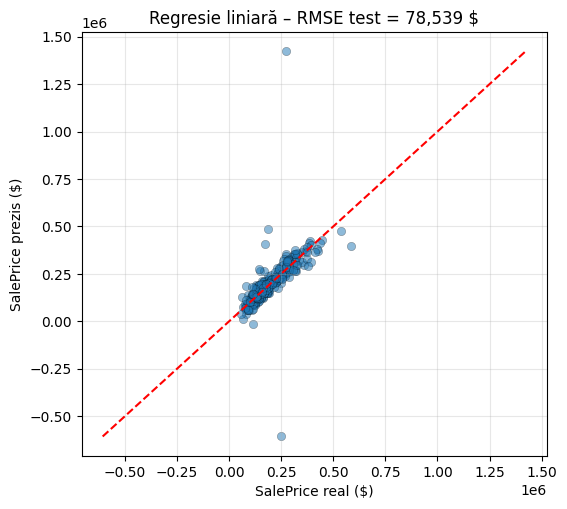

In [11]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression().fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print(f"RMSE regresie liniară  | train: {rmse(y_train, lr.predict(X_train)):,.0f} $ | test: {rmse(y_test, pred_lr):,.0f} $")

def plot_pred(ax, y, p, title):
    ax.scatter(y, p, alpha=.5, edgecolor='k', linewidth=.3)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    ax.plot(lim, lim, 'r--'); ax.set_xlabel('SalePrice real ($)'); ax.set_ylabel('SalePrice prezis ($)')
    ax.set_title(title); ax.grid(alpha=.3)

fig, ax = plt.subplots(figsize=(6, 5.5))
plot_pred(ax, y_test, pred_lr, f'Regresie liniară – RMSE test = {rmse(y_test, pred_lr):,.0f} $')
plt.show()

**Răspuns.** Regresia liniară de bază are RMSE de antrenare ≈ **20 209 $**, iar de test ≈ **78 539 $**: de aproape 4 ori mai mare. Cu 251 de caracteristici (multe corelate) pentru 965 de rânduri, modelul este supraadaptat, ca în laboratorul anterior. Graficul arată câteva predicții foarte departe de diagonală (inclusiv valori negative sau mult prea mari).

## Întrebarea 6

Regresia Ridge utilizează normalizarea L2 pentru a reduce magnitudinea coeficienților. Acest lucru poate fi util în situații în care există o varianță ridicată. Funcțiile de regularizare din Scikit-learn conțin fiecare versiuni care au validarea încrucișată încorporată.

* Adaptați un model Ridge regulat (nevalidat încrucișat) la o gamă de valori $\alpha$ și reprezentați grafic RMSE utilizând funcția de eroare validată încrucișat pe care ați creat-o mai sus.
* Utilizați $$[0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]$$ ca interval de alphas.
* Apoi repetați ajustarea modelelor Ridge folosind gama de valori $\alpha$ din secțiunea anterioară. Comparați rezultatele.

,RMSE CV (train),RMSE test
alpha,,
0.005,37370.0,41964.0
0.050,37017.0,40717.0
0.100,36852.0,39587.0
0.300,36604.0,37043.0
1.000,36235.0,34331.0
3.000,35589.0,32883.0
5.000,35225.0,32503.0
10.000,34801.0,32219.0
15.000,34647.0,32178.0


Cel mai bun alpha (după RMSE validat încrucișat): 30.0


,RMSE CV (train),RMSE test
alpha,,
10.000,34801.0,32219.0
13.161,34687.0,32181.0
17.321,34615.0,32187.0
22.795,34590.0,32238.0
30.000,34614.0,32333.0
39.482,34688.0,32470.0
51.962,34812.0,32647.0
68.385,34988.0,32859.0
90.000,35219.0,33103.0


Cel mai bun alpha (gama fină): 22.795


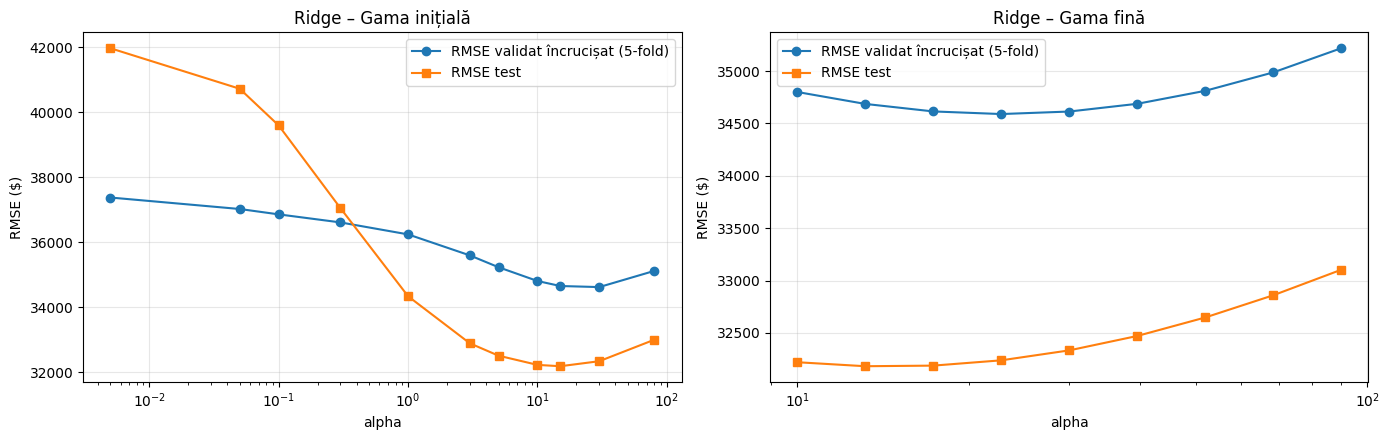

In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score

alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def ridge_curve(alphas):
    rows = []
    for a in alphas:
        m = Ridge(alpha=a).fit(X_train, y_train)
        cv = -cross_val_score(Ridge(alpha=a), X_train, y_train, cv=cv5, scoring=rmse_scorer).mean()
        rows.append({'alpha': a, 'RMSE CV (train)': cv, 'RMSE test': rmse(y_test, m.predict(X_test))})
    return pd.DataFrame(rows).set_index('alpha')

R1 = ridge_curve(alphas)
display(R1.round(0))
best_a = R1['RMSE CV (train)'].idxmin()
print(f"Cel mai bun alpha (după RMSE validat încrucișat): {best_a}")

# Repetăm într-o gamă fină în jurul celui mai bun alpha din secțiunea anterioară
fine = np.round(np.geomspace(best_a / 3, best_a * 3, 9), 3).tolist()
R2 = ridge_curve(fine)
display(R2.round(0))
best_fine = R2['RMSE CV (train)'].idxmin()
print(f"Cel mai bun alpha (gama fină): {best_fine}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, R, t in zip(ax, [R1, R2], ['Gama inițială', 'Gama fină']):
    a_.semilogx(R.index, R['RMSE CV (train)'], '-o', label='RMSE validat încrucișat (5-fold)')
    a_.semilogx(R.index, R['RMSE test'], '-s', label='RMSE test')
    a_.set_xlabel('alpha'); a_.set_ylabel('RMSE ($)'); a_.set_title(f'Ridge – {t}'); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Răspuns.** Regularizarea Ridge reduce dramatic eroarea de test: de la ≈ **78 539 $** (regresie liniară) la ≈ **32 200–32 300 $**, o îmbunătățire de ~59%.

- Gama dată: RMSE validat încrucișat este minim la **α = 30** (≈ 34 614 $). RMSE pe test este minim la α = 15 (≈ 32 178 $), dar diferența față de α = 30 (≈ 32 333 $) este neglijabilă.
- Gama fină din jurul optimului: cel mai bun α validat încrucișat este **≈ 22,8** (RMSE CV ≈ 34 590 $, test ≈ 32 238 $), practic același rezultat ca la α = 30. Curba este foarte plată în jur de α ≈ 10–40.
- Forma curbei: pentru α mic modelul se apropie de regresia liniară (supraadaptare), iar pentru α mare apare subadaptarea (eroarea crește ușor după ≈ 30). Valoarea optimă se află la mijloc, exact compromisul bias–varianță.

Acum, pentru metoda `RidgeCV`. Din păcate, nu este posibil să obținem valorile alfa pentru modelele care nu au fost selectate. Valorile erorilor și valorile $\alpha$ rezultate sunt foarte asemănătoare cu cele obținute mai sus.

In [13]:
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(alphas=alphas, scoring=rmse_scorer, cv=cv5).fit(X_train, y_train)
print("RidgeCV – alpha optim:", ridge_cv.alpha_)
print(f"RidgeCV – RMSE test  : {rmse(y_test, ridge_cv.predict(X_test)):,.0f} $")

RidgeCV – alpha optim: 30.0
RidgeCV – RMSE test  : 32,333 $


**Răspuns.** `RidgeCV` alege **α = 30** și obține RMSE test ≈ **32 333 $**, același rezultat ca în căutarea manuală de mai sus (cel mai bun α din gama dată).

## Întrebarea 7


La fel ca funcția `RidgeCV`, există și o funcție `LassoCV` care utilizează o funcție de regularizare L1 și validarea încrucișată. Regularizarea L1 va micșora selectiv anumiți coeficienți, efectuând efectiv eliminarea caracteristicilor.

Funcția `LassoCV` nu permite setarea funcției de scor. Cu toate acestea, funcția de eroare personalizată (`rmse`) creată mai sus poate fi utilizată pentru a evalua eroarea modelului final.

În mod similar, există și o funcție elastic net cu validare încrucișată, `ElasticNetCV`, care este o combinație de regularizare L2 și L1.

* Potriviți un model Lasso utilizând validarea încrucișată și determinați valoarea optimă pentru $\alpha$ și RMSE utilizând funcția creată mai sus. Rețineți că magnitudinea lui $\alpha$ poate fi diferită de cea a modelului Ridge.
* Repetați operația cu modelul de plasă elastică.
* Comparați rezultatele prin tabel și/sau grafic.

Utilizați următoarele alphas:

`[1e-5, 5e-5, 0.0001, 0.0005]`

In [14]:
from sklearn.linear_model import LassoCV, ElasticNetCV

alphas_l = [1e-5, 5e-5, 0.0001, 0.0005]
lasso_cv = LassoCV(alphas=alphas_l, cv=5, max_iter=200_000, random_state=RANDOM_STATE).fit(X_train, y_train)
print("LassoCV – alpha optim:", lasso_cv.alpha_)
print(f"LassoCV – RMSE test  : {rmse(y_test, lasso_cv.predict(X_test)):,.0f} $")

LassoCV – alpha optim: 0.0005
LassoCV – RMSE test  : 144,831 $


**Răspuns.** Cu gama de α dată (1e-5 … 5e-4), `LassoCV` alege **α = 0,0005**, adică chiar capătul superior al gamei, iar RMSE test este ≈ **144 831 $**, mult mai slab chiar decât regresia liniară. Cauza: caracteristicile nu sunt scalate (au ordine de mărime foarte diferite), așa că aceste valori de α sunt practic neregularizate (rămân 239 din 251 de coeficienți nenuli) și descendența pe coordonate converge greu. Gama dată este prea mică pentru datele nescalate; vezi observația suplimentară de mai jos.

Putem determina câte dintre aceste caracteristici rămân diferite de zero.

In [15]:
n_tot = len(lasso_cv.coef_)
n_nz = int((lasso_cv.coef_ != 0).sum())
print(f"Lasso: {n_nz} coeficienți nenuli din {n_tot} ({n_tot - n_nz} caracteristici eliminate)")
print("Ridge:", int((ridge_cv.coef_ != 0).sum()), "nenuli din", n_tot, "(Ridge nu elimină caracteristici)")

Lasso: 239 coeficienți nenuli din 251 (12 caracteristici eliminate)
Ridge: 241 nenuli din 251 (Ridge nu elimină caracteristici)


Încercați acum plasa elastică, cu aceleași alphas ca în Lasso, și l1_ratios între 0,1 și 0,9

In [16]:
enet_cv = ElasticNetCV(alphas=alphas_l, l1_ratio=[.1, .3, .5, .7, .9], cv=5,
                       max_iter=200_000, random_state=RANDOM_STATE).fit(X_train, y_train)
print("ElasticNetCV – alpha optim:", enet_cv.alpha_, "| l1_ratio optim:", enet_cv.l1_ratio_)
print(f"ElasticNetCV – RMSE test  : {rmse(y_test, enet_cv.predict(X_test)):,.0f} $")
print("Coeficienți nenuli:", int((enet_cv.coef_ != 0).sum()), "din", n_tot)

ElasticNetCV – alpha optim: 0.0005 | l1_ratio optim: 0.1
ElasticNetCV – RMSE test  : 36,122 $
Coeficienți nenuli: 241 din 251


Compararea calculului RMSE din toate modelele este cea mai ușoară într-un tabel.

In [17]:
models = {'Regresie liniară': lr, 'RidgeCV': ridge_cv, 'LassoCV': lasso_cv, 'ElasticNetCV': enet_cv}
summary = pd.DataFrame({
    name: {'alpha': getattr(m, 'alpha_', np.nan),
           'l1_ratio': getattr(m, 'l1_ratio_', np.nan),
           'RMSE train': rmse(y_train, m.predict(X_train)),
           'RMSE test': rmse(y_test, m.predict(X_test)),
           'coef. nenuli': int((m.coef_ != 0).sum())}
    for name, m in models.items()}).T
pd.options.display.float_format = '{:,.4f}'.format
display(summary)

,alpha,l1_ratio,RMSE train,RMSE test,coef. nenuli
Regresie liniară,NaN,NaN,"20,208.8624","78,539.1382",248.0000
RidgeCV,30.0000,NaN,"28,193.4950","32,332.5916",241.0000
LassoCV,0.0005,NaN,"20,215.1297","144,831.2570",239.0000
ElasticNetCV,0.0005,0.1000,"21,846.8434","36,122.3131",241.0000


**Răspuns.**

| Model | α | l1_ratio | RMSE train | RMSE test | coef. nenuli |
|---|---|---|---|---|---|
| Regresie liniară | – | – | 20 209 | 78 539 | 248 |
| RidgeCV | 30 | – | 28 193 | **32 333** | 241 |
| LassoCV (gama dată) | 0,0005 | – | 20 215 | 144 831 | 239 |
| ElasticNetCV (gama dată) | 0,0005 | 0,1 | 21 847 | 36 122 | 241 |

- **Ridge** oferă cel mai bun rezultat din modelele cu gama dată: reduce varianța, dar păstrează aproape toți coeficienții.
- **Lasso** (gama dată) nu regularizează suficient și este instabil pe date nescalate.
- **Elastic Net** alege cel mai mic l1_ratio (0,1), adică un amestec dominat de L2, și obține 36 122 $, aproape de Ridge: componenta L2 stabilizează modelul.
- Numărul de coeficienți nenuli este similar (≈ 240) pentru toate cele patru modele, deci cu aceste valori mici ale lui α nu se realizează o selecție semnificativă de caracteristici.

In [18]:
# Observație suplimentară: gama de alpha dată (1e-5 ... 5e-4) este prea mică pentru caracteristici NEscalate
# (cel mai bun alpha este chiar capătul gamei). Repetăm pe o gamă largă pentru a vedea efectul real al L1.
alphas_wide = np.geomspace(1e-2, 1e3, 10)
lasso_w = LassoCV(alphas=alphas_wide, cv=5, max_iter=200_000, random_state=RANDOM_STATE).fit(X_train, y_train)
enet_w  = ElasticNetCV(alphas=alphas_wide, l1_ratio=[.1, .5, .9], cv=5, max_iter=200_000,
                       random_state=RANDOM_STATE).fit(X_train, y_train)
wide = pd.DataFrame({
    'LassoCV (gamă largă)': {'alpha': lasso_w.alpha_, 'l1_ratio': np.nan, 'RMSE test': rmse(y_test, lasso_w.predict(X_test)),
                             'coef. nenuli': int((lasso_w.coef_ != 0).sum())},
    'ElasticNetCV (gamă largă)': {'alpha': enet_w.alpha_, 'l1_ratio': enet_w.l1_ratio_, 'RMSE test': rmse(y_test, enet_w.predict(X_test)),
                                  'coef. nenuli': int((enet_w.coef_ != 0).sum())}}).T
display(wide)

,alpha,l1_ratio,RMSE test,coef. nenuli
LassoCV (gamă largă),77.4264,NaN,"39,291.4475",119.0000
ElasticNetCV (gamă largă),0.1292,0.9000,"32,185.3963",241.0000


**Observație suplimentară.** Pe o gamă largă de α (0,01 … 1000), rezultatele se schimbă mult:
- **LassoCV** alege α ≈ **77** și obține RMSE test ≈ **39 291 $** (față de 144 831 $), cu doar **119 coeficienți nenuli din 251**: aici L1 elimină efectiv peste jumătate din caracteristici, cum spune cerința.
- **ElasticNetCV** alege α ≈ 0,13 și l1_ratio = 0,9 și obține RMSE test ≈ **32 185 $**, la nivelul Ridge (32 333 $), cu 241 de coeficienți nenuli.

Concluzie: pe aceste date, regularizarea contează mai mult decât tipul ei (L1/L2), iar gama de α trebuie adaptată la scara caracteristicilor (altfel, ca la gama dată, rezultatele pot fi înșelătoare).

Putem, de asemenea, să realizăm un grafic al prețurilor reale și previzionate ale locuințelor, la fel ca înainte.

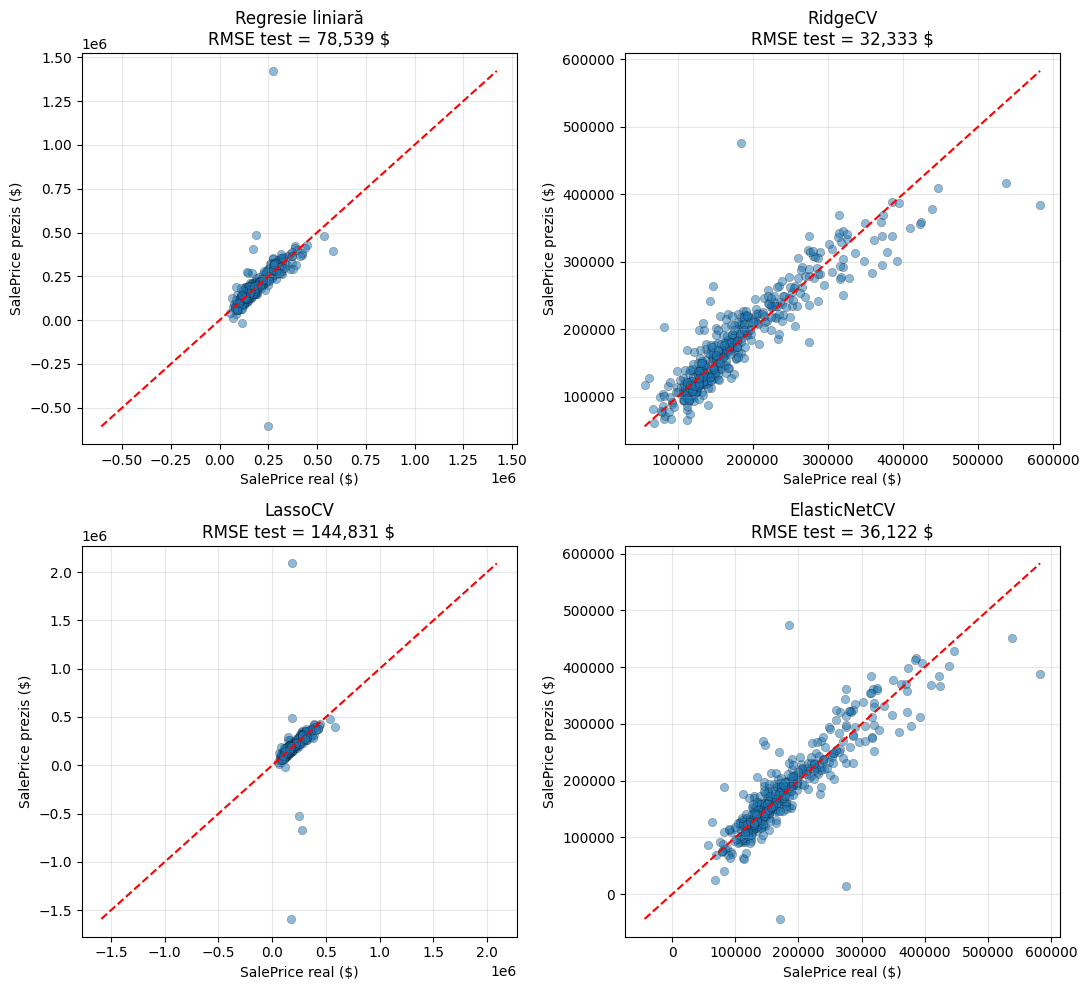

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax_, (name, m) in zip(axes.ravel(), models.items()):
    p = m.predict(X_test)
    plot_pred(ax_, y_test, p, f'{name}\nRMSE test = {rmse(y_test, p):,.0f} $')
plt.tight_layout(); plt.show()

## Întrebarea 8

Să explorăm coborârea stochastică a gradientului în acest exercițiu.  
Reamintim că modelele liniare în general sunt sensibile la scalare.
Cu toate acestea, SGD este *foarte* sensibil la scalare.  
În plus, o valoare mare a ratei de învățare poate determina algoritmul să devieze, în timp ce o valoare prea mică poate dura prea mult până la convergență.

* Potriviți un model stochastic gradient descent fără o penalizare de regularizare (parametrul relevant este `penalty`).
* Ajustați acum modele stochastice de coborâre în gradient cu fiecare dintre cele trei penalizări (L2, L1, Elastic Net) folosind valorile parametrilor determinate prin validarea încrucișată de mai sus. 
* Nu scalați datele înainte de ajustarea modelului.  
* Comparați rezultatele cu cele obținute fără a utiliza coborârea stochastică în gradient.

In [20]:
from sklearn.linear_model import SGDRegressor

# Parametrii din validarea încrucișată de mai sus
a_ridge, a_lasso, a_enet, l1r = ridge_cv.alpha_, lasso_cv.alpha_, enet_cv.alpha_, enet_cv.l1_ratio_

def sgd_configs(**extra):
    return {'fără penalizare': dict(penalty=None, **extra),
            'L2 (Ridge)':      dict(penalty='l2', alpha=a_ridge, **extra),
            'L1 (Lasso)':      dict(penalty='l1', alpha=a_lasso, **extra),
            'Elastic Net':     dict(penalty='elasticnet', alpha=a_enet, l1_ratio=l1r, **extra)}

def run_sgd(Xtr, Xte, **extra):
    rows = {}
    for name, p in sgd_configs(**extra).items():
        try:
            with np.errstate(all='ignore'):
                m = SGDRegressor(random_state=RANDOM_STATE, **p).fit(Xtr, y_train)
                rows[name] = {'RMSE train': rmse(y_train, m.predict(Xtr)), 'RMSE test': rmse(y_test, m.predict(Xte))}
        except ValueError as e:
            rows[name] = {'RMSE train': np.nan, 'RMSE test': np.nan}      # divergență (overflow)
    return pd.DataFrame(rows).T

pd.options.display.float_format = '{:,.0f}'.format
print("SGD FĂRĂ scalare, rata de învățare implicită (eta0=0.01):")
sgd_raw = run_sgd(X_train, X_test)
display(sgd_raw)

SGD FĂRĂ scalare, rata de învățare implicită (eta0=0.01):


,RMSE train,RMSE test
fără penalizare,"9,593,644,146,154,536","9,589,758,437,650,834"
L2 (Ridge),"3,208,556,468,574,254","3,207,466,409,615,889"
L1 (Lasso),"9,594,434,506,574,724","9,590,548,536,205,388"
Elastic Net,"697,016,563,240,147","695,679,271,343,667"


**Răspuns.** Fără scalare și cu rata de învățare implicită (`eta0 = 0,01`), **SGD diverge** pentru toate cele patru variante: RMSE de ordinul 10¹⁵–10¹⁶ (practic infinit). Caracteristici cu ordine de mărime foarte diferite (suprafețe de mii, ani ≈ 2000, indicatori 0/1) fac gradienții uriași, iar pașii de actualizare „sar” peste minim și amplifică eroarea la fiecare iterație. (Notă: problema este de regresie, deci folosim `SGDRegressor`; `SGDClassifier` din enunț nu se potrivește aici.) Penalizarea nu salvează situația: toate variantele diverg.

Observați cât de mari sunt valorile erorii! Algoritmul este divergent. Acest lucru se poate datora faptului că scalarea și/sau rata de învățare sunt prea mari. Să ajustăm rata de învățare și să vedem ce se întâmplă.

* Introduceți `eta0=1e-7` la crearea instanței de `SGDClassifier`.
* Calculați din nou erorile pentru toate penalitățile și comparați.

In [21]:
print("SGD FĂRĂ scalare, eta0 = 1e-7:")
sgd_eta = run_sgd(X_train, X_test, eta0=1e-7)
display(sgd_eta)

SGD FĂRĂ scalare, eta0 = 1e-7:


,RMSE train,RMSE test
fără penalizare,"77,667","74,750"
L2 (Ridge),"77,674","74,759"
L1 (Lasso),"77,667","74,750"
Elastic Net,"77,667","74,750"


**Răspuns.** Cu `eta0 = 1e-7` divergența dispare, dar modelul **abia învață**: RMSE test ≈ **74 750 $** (≈ abaterea standard a prețului, 79 000 $) pentru toate penalizările, aproape de predicția mediei. Rata este atât de mică încât, în limita iterațiilor, ponderile nu ajung la valori utile (**subadaptare**). Fără scalare nu există o rată de învățare bună, pentru că fiecare caracteristică ar avea nevoie de alt pas.

Acum să ne scalăm datele de antrenament și să încercăm din nou.

* Adaptați un `MinMaxScaler` la `X_train` și creați o variabilă `X_train_scaled`.
* Folosind scala, transformați `X_test` și creați o variabilă `X_test_scaled`. 
* Aplicați-le aceleași versiuni ale SGD și comparați rezultatele. De data aceasta nu introduceți un eta0.

In [22]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("SGD CU MinMaxScaler, rata de învățare implicită:")
sgd_scaled = run_sgd(X_train_scaled, X_test_scaled)
display(sgd_scaled)

# Comparație finală cu modelele fără SGD
final = pd.DataFrame({
    'Regresie liniară (OLS)': rmse(y_test, lr.predict(X_test)),
    'RidgeCV': rmse(y_test, ridge_cv.predict(X_test)),
    'LassoCV': rmse(y_test, lasso_cv.predict(X_test)),
    'ElasticNetCV': rmse(y_test, enet_cv.predict(X_test)),
}, index=['RMSE test']).T
sgd_cmp = pd.DataFrame({'SGD fără scalare': sgd_raw['RMSE test'],
                        'SGD fără scalare, eta0=1e-7': sgd_eta['RMSE test'],
                        'SGD scalat (MinMax)': sgd_scaled['RMSE test']})
print("\nRMSE test – modele fără SGD:")
display(final)
print("RMSE test – modele SGD (pe linii: penalizarea):")
display(sgd_cmp)

SGD CU MinMaxScaler, rata de învățare implicită:


,RMSE train,RMSE test
fără penalizare,"26,509","32,666"
L2 (Ridge),"77,341","75,074"
L1 (Lasso),"26,509","32,666"
Elastic Net,"26,557","32,634"



RMSE test – modele fără SGD:


,RMSE test
Regresie liniară (OLS),"78,539"
RidgeCV,"32,333"
LassoCV,"144,831"
ElasticNetCV,"36,122"


RMSE test – modele SGD (pe linii: penalizarea):


,SGD fără scalare,"SGD fără scalare, eta0=1e-7",SGD scalat (MinMax)
fără penalizare,"9,589,758,437,650,834","74,750","32,666"
L2 (Ridge),"3,207,466,409,615,889","74,759","75,074"
L1 (Lasso),"9,590,548,536,205,388","74,750","32,666"
Elastic Net,"695,679,271,343,667","74,750","32,634"


**Răspuns.** După `MinMaxScaler` (ajustat pe train) SGD funcționează cu rata implicită:
- fără penalizare, L1 și Elastic Net: RMSE test ≈ **32 600–32 700 $**, la nivelul RidgeCV (32 333 $) și al Elastic Net (32 185 $ pe gama largă) și mult mai bun decât regresia liniară (78 539 $). Probabil SGD, oprit după un număr limitat de epoci/toleranță, nu atinge soluția OLS supraadaptată, deci acționează ca o regularizare implicită („early stopping”).
- L2 cu α = 30 (valoarea de la RidgeCV): RMSE test ≈ **75 074 $**, adică supra-regularizat. Parametrul `alpha` din SGD multiplică penalizarea față de pierderea *medie* pe exemplu, nu față de suma pierderilor ca în `Ridge`, deci aceeași valoare numerică înseamnă o regularizare mult mai puternică. Pentru SGD valoarea lui α ar trebui reajustată separat.

**Comparație generală (RMSE test):** SGD scalat ≈ 32,6 mii $ ≈ RidgeCV 32,3 mii $ < Elastic Net 36,1 mii $ (gama dată) < regresie liniară 78,5 mii $ < Lasso 144,8 mii $ (gama dată); SGD nescalat diverge sau subadaptează. Lecția: **SGD este foarte sensibil la scalare și la rata de învățare**, iar scalarea datelor este obligatorie.